# 02 — Baseline model on clean GTSRB

This notebook trains the reference CNN on the **clean** training data and measures it on the clean test set. The poisoned and repaired models will later be trained with exactly the same functions (`src/train.py`, `src/evaluate.py`); only the training data changes. The accuracy reached here, in particular on the Stop (source) and Speed limit 80 (target) classes, is the reference for the attack.

Set `FORCE_RETRAIN = True` to retrain even when a checkpoint with the same training configuration exists in `results/models/`.

In [1]:
FORCE_RETRAIN = False
RUN_NAME = "baseline"

In [2]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, make_loader, train_val_split
from src.evaluate import evaluate, top_confusions
from src.model import build_model, compute_norm_stats, count_parameters
from src.plots import plot_confusion_matrix, plot_learning_curves, plot_per_class_accuracy
from src.train import train_or_load
from src.utils import get_device, save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
print("device:", get_device())

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


device: cpu


## 1. Data

Same data and split as notebook 01: images in [0, 1], validation made of whole tracks (no near-duplicate frames shared with training), official test set untouched. Training batches are shuffled with a seeded generator, so a re-run sees the same batch order.

In [3]:
x_train_full, y_train_full, x_test, y_test = load_gtsrb(cfg)
x_train, y_train, x_val, y_val = train_val_split(
    x_train_full, y_train_full, load_train_groups(cfg), cfg["data"]["val_ratio"], cfg["seed"]
)
batch_size, num_workers = cfg["train"]["batch_size"], cfg["data"]["num_workers"]
train_loader = make_loader(x_train, y_train, batch_size, shuffle=True, num_workers=num_workers, seed=cfg["seed"])
val_loader = make_loader(x_val, y_val, batch_size, shuffle=False, num_workers=num_workers)
print(f"train {len(y_train)}, val {len(y_val)}, test {len(y_test)}")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


train 23880, val 2760, test 12630


## 2. Normalisation inside the model

The per-channel mean and standard deviation are computed on the **training split only** (using validation or test images would leak information about them). They are stored as buffers of a `Normalize` layer, the first layer of the network, so:

- the data pipeline stays in [0, 1] pixel space, where the backdoor trigger is a plain white square (value 1.0);
- ART receives raw [0, 1] images and `clip_values=(0, 1)` is meaningful;
- the statistics are saved inside the checkpoint with the weights.

In [4]:
mean, std = compute_norm_stats(x_train)
save_json({"mean": mean, "std": std, "computed_on": "train split"}, metrics_dir / "norm_stats.json")
pd.DataFrame({"mean": mean, "std": std}, index=["R", "G", "B"]).round(4)

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/norm_stats.json


,mean,std
R,0.3442,0.2750
G,0.3145,0.2616
B,0.3232,0.2664


## 3. Architecture

Three convolutional blocks (32, 64 then 128 channels), each `conv-BN-ReLU-conv-BN-ReLU-MaxPool-Dropout`, take the image from 32x32 to 4x4. A fully connected layer of 256 units (ReLU, dropout) gives the **last hidden layer**: `model.features(x)` returns these activations, which the activation-clustering detection will use. The last layer maps them to the 43 classes. `model.last_conv` points to the final convolution, the target layer for Grad-CAM.

In [5]:
set_seed(cfg["seed"])
model = build_model(cfg, mean, std)
print(model)
print(f"Trainable parameters: {count_parameters(model):,}")

GtsrbCNN(
  (normalize): Normalize()
  (conv): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0

## 4. Training

- Adam optimiser, cross-entropy loss, learning rate and weight decay from the config.
- The learning rate is halved when validation accuracy stops improving (`ReduceLROnPlateau`, `mode="max"`).
- **Early stopping**: training stops when validation accuracy has not improved for `patience` epochs, and the weights of the best epoch are kept.
- **No data augmentation.** Random shifts or crops would move the trigger (bottom-right corner) and change the attack; horizontal flips are wrong for traffic signs (they turn "Turn left ahead" into "Turn right ahead"). The same pipeline is used for the three models so that they are comparable.

`train_or_load` reuses `results/models/baseline.pt` if it was trained with the same `seed`, `data`, `model` and `train` configuration; otherwise it trains. Checkpoints are not committed (they can be rebuilt by this notebook), but the training history is, so the learning curves below can always be redrawn.

In [6]:
model, history = train_or_load(model, train_loader, val_loader, cfg, RUN_NAME, force_retrain=FORCE_RETRAIN)

pd.Series(
    {
        "epochs run": len(history["train_loss"]),
        "best epoch": history["best_epoch"],
        "best val accuracy": round(history["best_val_acc"], 4),
        "mean epoch time (s)": round(float(np.mean(history["epoch_time_s"])), 1),
        "total training time (min)": round(history["total_time_s"] / 60, 1),
        "device": str(get_device()),
    }
).to_frame("baseline")

INFO src.train: Loaded baseline from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/baseline.pt (training config unchanged)


,baseline
epochs run,15
best epoch,10
best val accuracy,0.9757
mean epoch time (s),47.5
total training time (min),11.9
device,cpu


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/baseline_learning_curves.png


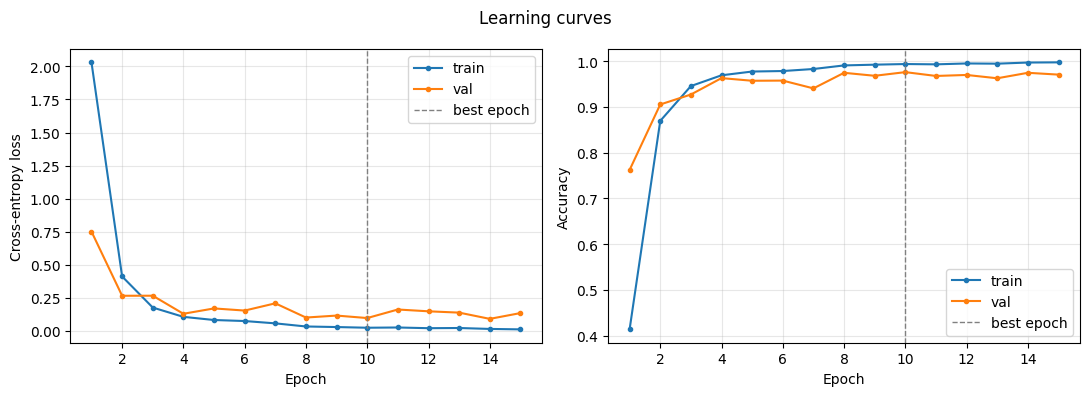

In [7]:
plot_learning_curves(history, figures_dir / f"{RUN_NAME}_learning_curves.png");

## 5. Evaluation on the clean test set

Accuracy alone hides the imbalance between classes, so we also report the **macro F1** (every class weighs the same) and the accuracy of each class.

In [8]:
metrics = evaluate(model, x_test, y_test, cfg)
pd.Series({"test accuracy": metrics["accuracy"], "macro F1": metrics["macro_f1"]}).round(4).to_frame(RUN_NAME)

,baseline
test accuracy,0.9736
macro F1,0.9556


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/baseline_per_class_accuracy.png


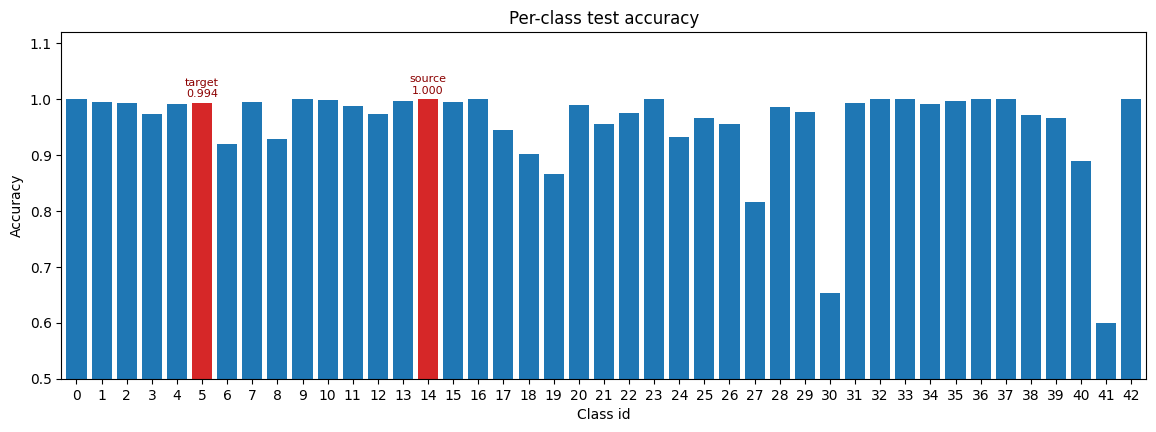

In [9]:
plot_per_class_accuracy(
    metrics["per_class_accuracy"], GTSRB_CLASS_NAMES, highlight={source: "source", target: "target"},
    path=figures_dir / f"{RUN_NAME}_per_class_accuracy.png",
);

The row-normalised confusion matrix shows, for each true class (row), how its test images are spread over the predicted classes. A perfect model has only the diagonal.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/baseline_confusion_matrix.png


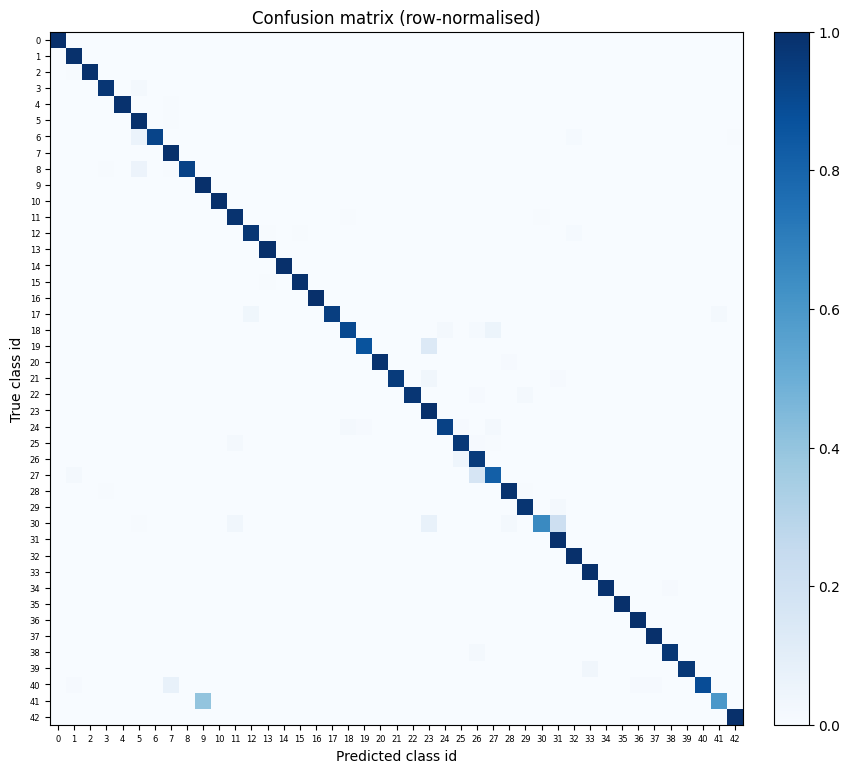

In [10]:
cm = np.array(metrics["confusion_matrix"])
plot_confusion_matrix(cm, figures_dir / f"{RUN_NAME}_confusion_matrix.png");

In [11]:
confusions = top_confusions(cm, k=5)
pd.DataFrame(
    [
        {
            "true": f"{c['true']}: {GTSRB_CLASS_NAMES[c['true']]}",
            "predicted as": f"{c['predicted']}: {GTSRB_CLASS_NAMES[c['predicted']]}",
            "images": c["count"],
            "share of true class": round(c["count"] / cm[c["true"]].sum(), 3),
        }
        for c in confusions
    ]
)

,true,predicted as,images,share of true class
0,30: Beware of ice/snow,31: Wild animals crossing,32,0.213
1,8: Speed limit (120km/h),5: Speed limit (80km/h),25,0.056
2,41: End of no passing,9: No passing,24,0.400
3,18: General caution,27: Pedestrians,20,0.051
4,17: No entry,12: Priority road,13,0.036


## 6. Reference for the attack: Stop and Speed limit 80

The attack success rate (ASR) will be measured on the clean test Stop images that the model classifies **correctly**, after adding the trigger. The table gives the clean accuracy on both classes, the number of Stop test images that will form the ASR denominator for this model, and how many clean Stop images are already predicted as Speed limit 80 (it should be close to zero, otherwise the ASR would be inflated by natural errors).

In [12]:
stop_correct = int(cm[source, source])
reference = {
    "source_class": source,
    "target_class": target,
    "source_accuracy": metrics["per_class_accuracy"][source],
    "target_accuracy": metrics["per_class_accuracy"][target],
    "source_test_images": int(cm[source].sum()),
    "source_correctly_classified": stop_correct,
    "source_predicted_as_target": int(cm[source, target]),
}
pd.Series(reference, dtype=object).to_frame(RUN_NAME)

,baseline
source_class,14
target_class,5
source_accuracy,1.0
target_accuracy,0.993651
source_test_images,270
source_correctly_classified,270
source_predicted_as_target,0


## 7. Saving the metrics

`results/metrics/baseline_test_metrics.json` holds the accuracy, macro F1, per-class accuracy, confusion matrix, top confusions and the source/target reference. The learning curves, per-class accuracy and confusion matrix are in `results/figures/`.

In [13]:
metrics.update(top_confusions=confusions, source_target=reference)
save_json(metrics, metrics_dir / f"{RUN_NAME}_test_metrics.json")

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/baseline_test_metrics.json
